# Random Forest vs AdaBoost

Comparing bagging and boosting ensembles on the Iris dataset.

In [ ]:
import pandas as pd
from sklearn.datasets import load_iris
import seaborn as sns
import matplotlib.pyplot as plt

# Loading the Iris dataset
data = load_iris()
df = pd.DataFrame(data.data, columns=data.feature_names)
df['species'] = data.target

df.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),species
0,5.1,3.5,1.4,0.2,0
1,4.9,3.0,1.4,0.2,0
2,4.7,3.2,1.3,0.2,0
3,4.6,3.1,1.5,0.2,0
4,5.0,3.6,1.4,0.2,0


In [16]:
df.describe()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),species
count,150.000000,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.057333,3.758000,1.199333,1.000000
std,0.828066,0.435866,1.765298,0.762238,0.819232
min,4.300000,2.000000,1.000000,0.100000,0.000000
25%,5.100000,2.800000,1.600000,0.300000,0.000000
50%,5.800000,3.000000,4.350000,1.300000,1.000000
75%,6.400000,3.300000,5.100000,1.800000,2.000000
max,7.900000,4.400000,6.900000,2.500000,2.000000


In [17]:
df.isnull().sum()

sepal length (cm)    0
sepal width (cm)     0
petal length (cm)    0
petal width (cm)     0
species              0
dtype: int64

In [18]:
df_cleaned=df.drop_duplicates()
df_cleaned.duplicated().sum()


0

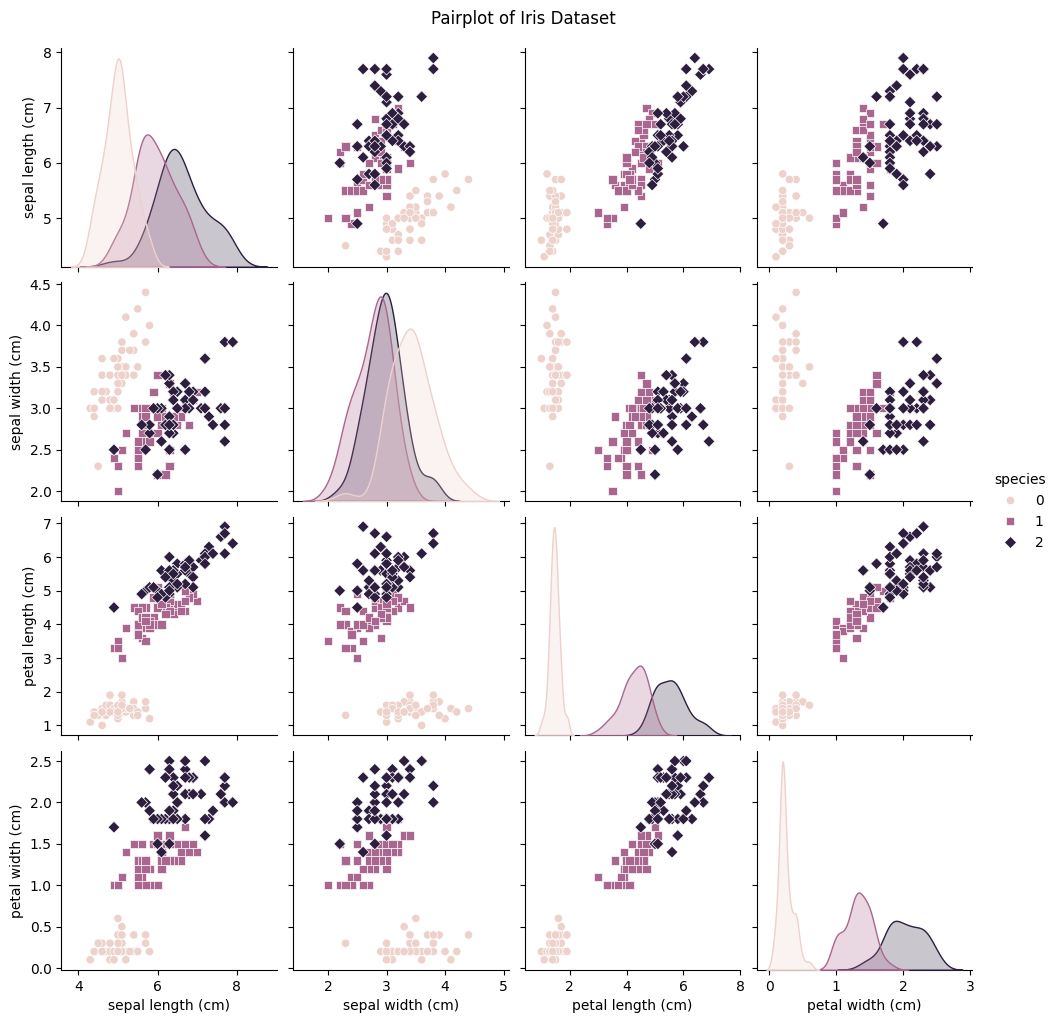

In [19]:
sns.pairplot(df_cleaned, hue='species', markers=["o", "s", "D"])
plt.suptitle("Pairplot of Iris Dataset", y=1.02)
plt.show()


In [ ]:
from sklearn.model_selection import train_test_split

# Defining features and target variable
X = df_cleaned.drop("species", axis=1)
y = df_cleaned["species"]

# Performing stratified train-test split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

print("Training set class distribution:\n", y_train.value_counts())
print("\nTest set class distribution:\n", y_test.value_counts())


Training set class distribution:
 species
0    40
1    40
2    39
Name: count, dtype: int64

Test set class distribution:
 species
1    10
2    10
0    10
Name: count, dtype: int64


In [ ]:
from sklearn.preprocessing import StandardScaler

# Standardizing the data
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)


In [22]:
from sklearn.ensemble import RandomForestClassifier

# Bagging with Random Forest
bagging_model = RandomForestClassifier(n_estimators=100, random_state=42)
bagging_model.fit(X_train_scaled, y_train)


RandomForestClassifier(random_state=42)

In [23]:
from sklearn.ensemble import AdaBoostClassifier

# Boosting with AdaBoost
boosting_model = AdaBoostClassifier(n_estimators=50, random_state=42)
boosting_model.fit(X_train_scaled, y_train)


AdaBoostClassifier(random_state=42)

In [24]:
from sklearn.metrics import accuracy_score, classification_report

# Predictions
y_pred_bagging = bagging_model.predict(X_test_scaled)
y_pred_boosting = boosting_model.predict(X_test_scaled)

# Evaluation
print("Bagging (Random Forest) Model Accuracy:", accuracy_score(y_test, y_pred_bagging))
print("Boosting (AdaBoost) Model Accuracy:", accuracy_score(y_test, y_pred_boosting))


Bagging (Random Forest) Model Accuracy: 0.9333333333333333
Boosting (AdaBoost) Model Accuracy: 0.9333333333333333


In [25]:
print("\nBagging Model Classification Report:\n", classification_report(y_test, y_pred_bagging))

print("\nBoosting Model Classification Report:\n",classification_report(y_test, y_pred_boosting))



Bagging Model Classification Report:
               precision    recall  f1-score   support

           0       1.00      1.00      1.00        10
           1       0.90      0.90      0.90        10
           2       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted avg       0.93      0.93      0.93        30


Boosting Model Classification Report:
               precision    recall  f1-score   support

           0       1.00      1.00      1.00        10
           1       0.90      0.90      0.90        10
           2       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted avg       0.93      0.93      0.93        30



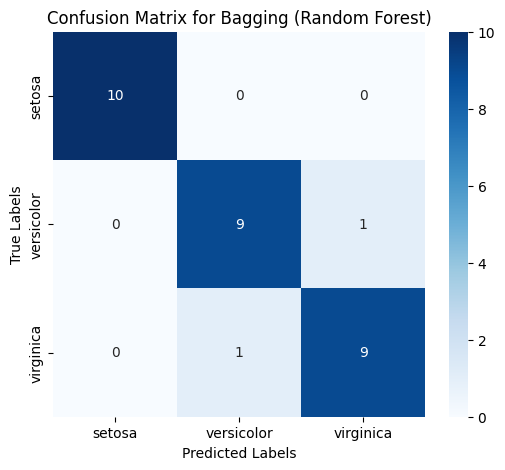

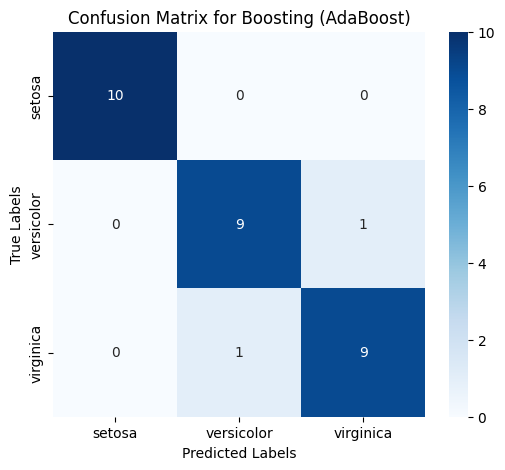

In [ ]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

# Confusion matrix for Bagging (Random Forest) Model
cm_bagging = confusion_matrix(y_test, y_pred_bagging)

# Confusion matrix for Boosting (AdaBoost) Model
cm_boosting = confusion_matrix(y_test, y_pred_boosting)

# Function to plot confusion matrix
def plot_confusion_matrix(cm, title):
    plt.figure(figsize=(6, 5))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=data.target_names, yticklabels=data.target_names)
    plt.title(title)
    plt.xlabel('Predicted Labels')
    plt.ylabel('True Labels')
    plt.show()

# Ploting confusion matrices
plot_confusion_matrix(cm_bagging, 'Confusion Matrix for Bagging (Random Forest)')
plot_confusion_matrix(cm_boosting, 'Confusion Matrix for Boosting (AdaBoost)')


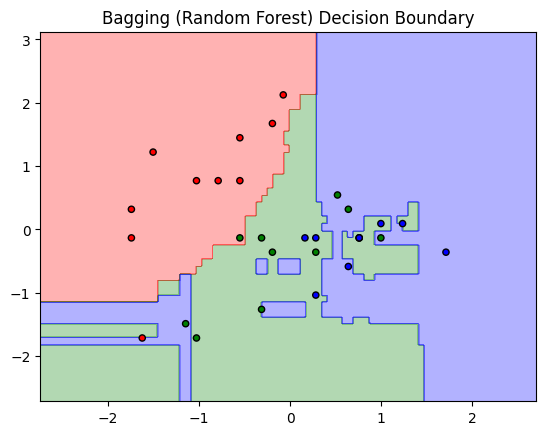

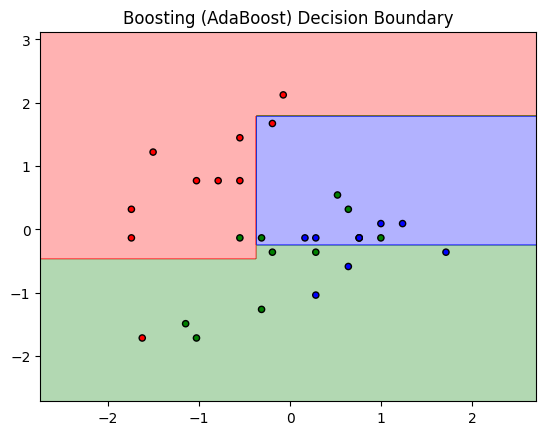

In [ ]:
import numpy as np
from matplotlib.colors import ListedColormap

def plot_decision_boundaries(model, X, y, title):
    x_min, x_max = X[:, 0].min() - 1, X[:, 0].max() + 1
    y_min, y_max = X[:, 1].min() - 1, X[:, 1].max() + 1
    xx, yy = np.meshgrid(np.arange(x_min, x_max, 0.02),
                            np.arange(y_min, y_max, 0.02))

    Z = model.predict(np.c_[xx.ravel(), yy.ravel()])
    Z = Z.reshape(xx.shape)
    
    plt.contourf(xx, yy, Z, alpha=0.3, cmap=ListedColormap(('red', 'green', 'blue')))
    plt.scatter(X[:, 0], X[:, 1], c=y, s=20, edgecolor='k', cmap=ListedColormap(('red', 'green', 'blue')))
    plt.title(title)
    plt.show()

# Usiing only the first two features for easy visualization
X_train_2d = X_train_scaled[:, :2]
X_test_2d = X_test_scaled[:, :2]

# Fiting models on 2D subset for visualization
bagging_model.fit(X_train_2d, y_train)
boosting_model.fit(X_train_2d, y_train)

# Ploting decision boundaries
plot_decision_boundaries(bagging_model, X_test_2d, y_test, title="Bagging (Random Forest) Decision Boundary")
plot_decision_boundaries(boosting_model, X_test_2d, y_test, title="Boosting (AdaBoost) Decision Boundary")

